# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

Ответ

Обучала YOLO26n на RTX 5060 Laptop с 8 ГБ видеопамяти. Использовала веса yolo26n.pt и Ultralytics 8.4.0.

Датасет Aquarium Combined v2 (raw-1024) от Roboflow, лицензия CC BY 4.0. Адрес записан в DATASET_NAME. Изображения и разметку взяла из копии GLIP/ODinW. Использовала шаблон ДЗ2, документацию Ultralytics и ONNX Runtime.

Выполнила задания с 1.1 по 5.3 и бонусы с 6.2 по 6.5.


In [1]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.0'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

assert ultralytics.__version__ == '8.4.0', 'Установите ultralytics==8.4.0'
assert torch.cuda.is_available(), 'Для этого эксперимента требуется локальная CUDA GPU'
DEVICE = 0
torch.cuda.set_device(DEVICE)
torch.set_num_threads(4)
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')
print('Python:', sys.executable)
print('CUDA:', torch.version.cuda, 'VRAM GiB:', torch.cuda.get_device_properties(DEVICE).total_memory / 2**30)
x_gpu = torch.randn(256, 256, device='cuda')
print('CUDA matmul:', (x_gpu @ x_gpu).mean().item())
torch.cuda.synchronize()


ultralytics 8.4.0, torch 2.11.0+cu128, device: NVIDIA GeForce RTX 5060 Laptop GPU
Python: C:\Users\ninak\PycharmProjects\dl-hw2\.venv\Scripts\python.exe
CUDA: 12.8 VRAM GiB: 7.93304443359375


CUDA matmul: 0.02286953292787075


In [2]:
import uuid

FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUN_ID = uuid.uuid4().hex
RUNS = Path('runs_hw2') / ('fast' if FAST_MODE else 'full') / RUN_ID
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
# ваш код
MODEL_INFO = dict(ultralytics=ultralytics.__version__, weights=weights_path.name,
                  sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
                  size_mb=weights_path.stat().st_size / 1e6,
                  params=sum(p.numel() for p in model_coco.model.parameters()),
                  n_classes_coco=len(model_coco.names))
latency_image = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
def latency_predict(detector, image, repeats=20, **kw):
    for _ in range(5):
        detector.predict(image, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw)
    times = []
    for _ in range(repeats):
        torch.cuda.synchronize()
        start = time.perf_counter()
        detector.predict(image, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw)
        torch.cuda.synchronize()
        times.append((time.perf_counter() - start) * 1000)
    return dict(mean_ms=float(np.mean(times)), std_ms=float(np.std(times)), repeats=repeats, warmup=5)
MODEL_INFO['latency'] = latency_predict(model_coco, latency_image)
MODEL_INFO['latency_ms'] = MODEL_INFO['latency']['mean_ms']

In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.0',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.544453,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency': {'mean_ms': 29.449835000559688,
  'std_ms': 7.7299060625262195,
  'repeats': 20,
  'warmup': 5},
 'latency_ms': 29.449835000559688}

Ответ

Я выбрала YOLO26n, чтобы дважды обучить модель на своей карте с 8 ГБ памяти. Для основного прогона оставила размер 640: почти 59% боксов в train занимают меньше 1% кадра.

На COCO у YOLO26s выше mAP50-95: 47,8% против 40,1% у YOLO26n в режиме без NMS. Зато у n примерно в четыре раза меньше параметров (2,4 млн против 9,5 млн). На T4 с TensorRT в таблице Ultralytics у n указано 1,7 мс на кадр, у s 2,5 мс. На своей карте я замерила полный вызов predict: в среднем 29,45 мс после прогрева.

У кода и весов Ultralytics лицензия AGPL-3.0. При публикации производной работы нужно предоставить её исходный код.


## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    # ваш код
    groups = dict(backbone=layers[:n_backbone], neck=layers[n_backbone:-1], head=layers[-1:])
    return {name: sum(p.numel() for layer in group for p in layer.parameters()) for name, group in groups.items()}


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    # ваш код
    device = next(det_model.parameters()).device
    features = []
    def capture(module, args):
        features.extend(tuple(t.shape) for t in args[0])
    training = det_model.training
    handle = det_model.model[-1].register_forward_pre_hook(capture)
    try:
        det_model.eval()
        with torch.inference_mode():
            output = det_model(torch.zeros(1, 3, imgsz, imgsz, device=device))
    finally:
        handle.remove()
        det_model.train(training)
    return features, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
# ваш код
print(shapes(out))
assert total == MODEL_INFO['params']

[(1, 300, 6), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


Ответ

Backbone выделяет признаки, а neck объединяет карты разных масштабов. Для входа 640 × 640 их размеры 80 × 80, 40 × 40 и 20 × 20 (шаги 8, 16 и 32). Если сложить число точек на этих картах, получится 8400. Head для каждой точки предсказывает расстояния до четырёх сторон бокса и оценки классов. Модель называется anchor-free, потому что строит боксы без заранее заданных шаблонов.

При обучении one2many назначает объекту несколько кандидатов, а one2one назначает одного. На предсказании используется one2one, поэтому можно выбрать лучшие детекции без NMS. Я насчитала 53,08% параметров в backbone, 34,88% в neck и 12,04% в head.


---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
# ваш код
import urllib.request
import urllib.parse
import zipfile
from concurrent.futures import ThreadPoolExecutor
from collections import defaultdict
import yaml

DATASET_NAME = 'Aquarium Combined v2 raw-1024; https://universe.roboflow.com/brad-dwyer/aquarium-combined/dataset/2; CC BY 4.0'
SOURCE_REVISION = '66ee3ae9a3b8cee0cf78f10ef5fc9a3725db02a1'
SOURCE_PREFIX = 'odinw/Aquarium/Aquarium Combined.v2-raw-1024.coco'
RAW_ROOT = DATA_ROOT / 'aquarium_v2'

def download_public(relative, destination):
    url = 'https://huggingface.co/GLIPModel/GLIP/resolve/' + SOURCE_REVISION + '/' + urllib.parse.quote(SOURCE_PREFIX + '/' + relative)
    destination = Path(destination)
    if destination.exists():
        return
    destination.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(4):
        try:
            with urllib.request.urlopen(url, timeout=90) as response:
                content = response.read()
            temporary = destination.with_suffix(destination.suffix + '.part')
            temporary.write_bytes(content)
            temporary.replace(destination)
            return
        except Exception:
            if attempt == 3:
                raise RuntimeError('Не удалось загрузить публичный файл: ' + relative) from None
            time.sleep(attempt + 1)

def prepare_dataset():
    RAW_ROOT.mkdir(parents=True, exist_ok=True)
    archive = os.getenv('AQUARIUM_ZIP')
    key = os.getenv('ROBOFLOW_API_KEY')
    if archive or key:
        if not archive:
            archive = DATA_ROOT / 'aquarium_download.zip'
            try:
                api = 'https://api.roboflow.com/brad-dwyer/aquarium-combined/2/coco?api_key=' + urllib.parse.quote(key)
                with urllib.request.urlopen(api, timeout=90) as response:
                    link = json.load(response)['export']['link']
                with urllib.request.urlopen(link, timeout=180) as response:
                    Path(archive).write_bytes(response.read())
            except Exception:
                raise RuntimeError('Roboflow: загрузка не удалась; проверьте ключ либо задайте AQUARIUM_ZIP') from None
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                target = (RAW_ROOT / member.filename).resolve()
                if not target.is_relative_to(RAW_ROOT.resolve()):
                    raise ValueError('Недопустимый путь в ZIP')
            z.extractall(RAW_ROOT)
        for split in ('train', 'valid', 'test'):
            candidates = list(RAW_ROOT.rglob(split + '/_annotations.coco.json'))
            if not (RAW_ROOT / split / '_annotations.coco.json').exists() and len(candidates) == 1:
                shutil.copytree(candidates[0].parent, RAW_ROOT / split, dirs_exist_ok=True)
    else:
        for split in ('train', 'valid', 'test'):
            download_public(split + '/_annotations.coco.json', RAW_ROOT / split / '_annotations.coco.json')
        for name in ('README.dataset.txt', 'README.roboflow.txt'):
            download_public(name, RAW_ROOT / name)
    jobs = []
    for split in ('train', 'valid', 'test'):
        annotation = json.loads((RAW_ROOT / split / '_annotations.coco.json').read_text())
        jobs.extend((split + '/' + image['file_name'], RAW_ROOT / split / image['file_name']) for image in annotation['images'])
    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(lambda job: download_public(*job), jobs))

prepare_dataset()
raw_annotations = {s: json.loads((RAW_ROOT / directory / '_annotations.coco.json').read_text())
                   for s, directory in [('train', 'train'), ('val', 'valid'), ('test', 'test')]}
categories = sorted((c for c in raw_annotations['train']['categories'] if c['name'] != 'creatures'), key=lambda c: c['id'])
CLASSES = [c['name'] for c in categories]
category_to_label = {c['id']: i for i, c in enumerate(categories)}
records = {}
CLEANING = {}
DATA_MANIFEST = {}
for split, annotation in raw_annotations.items():
    by_image = defaultdict(list)
    for a in annotation['annotations']:
        by_image[a['image_id']].append(a)
    recs = []
    clipped = removed = 0
    directory = 'valid' if split == 'val' else split
    for image in annotation['images']:
        path = RAW_ROOT / directory / image['file_name']
        with Image.open(path) as im:
            width, height = im.size
        assert (width, height) == (image['width'], image['height'])
        boxes, labels = [], []
        for a in by_image[image['id']]:
            assert a['category_id'] in category_to_label
            x, y, w, h = a['bbox']
            original = np.array([x, y, x + w, y + h], dtype=float)
            box = np.clip(original, [0, 0, 0, 0], [width, height, width, height])
            clipped += int(not np.array_equal(box, original))
            if not np.isfinite(box).all() or box[2] <= box[0] or box[3] <= box[1]:
                removed += 1
                continue
            boxes.append(box)
            labels.append(category_to_label[a['category_id']])
        recs.append(dict(image=path, width=width, height=height,
                         boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4), labels=np.asarray(labels, dtype=np.int64)))
    records[split] = recs
    CLEANING[split] = dict(clipped=clipped, removed=removed)
    DATA_MANIFEST[split] = dict(images=len(recs), annotation_sha256=hashlib.sha256((RAW_ROOT / directory / '_annotations.coco.json').read_bytes()).hexdigest())
assert {s: len(r) for s, r in records.items()} == {'train': 448, 'val': 127, 'test': 63}
print('Классы:', CLASSES)
print('Очистка:', CLEANING)
print('Манифест:', DATA_MANIFEST)

Классы: ['fish', 'jellyfish', 'penguin', 'puffin', 'shark', 'starfish', 'stingray']
Очистка: {'train': {'clipped': 0, 'removed': 0}, 'val': {'clipped': 0, 'removed': 0}, 'test': {'clipped': 0, 'removed': 2}}
Манифест: {'train': {'images': 448, 'annotation_sha256': '704a857b29cf4c270a0f4615d5623a9bf6e4c2b5fcc4eac30fcd0e349ab1d3cd'}, 'val': {'images': 127, 'annotation_sha256': 'ec4835501dec379f4dbc4a5be9e7bb8ffe1a90195d1670cb472524395f16eb0a'}, 'test': {'images': 63, 'annotation_sha256': 'a1aec1c033a208ec77a6d424a6db56ab840d423a5e65f82ac6ce693d65d281a4'}}


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 448, 'val': 127, 'test': 63}

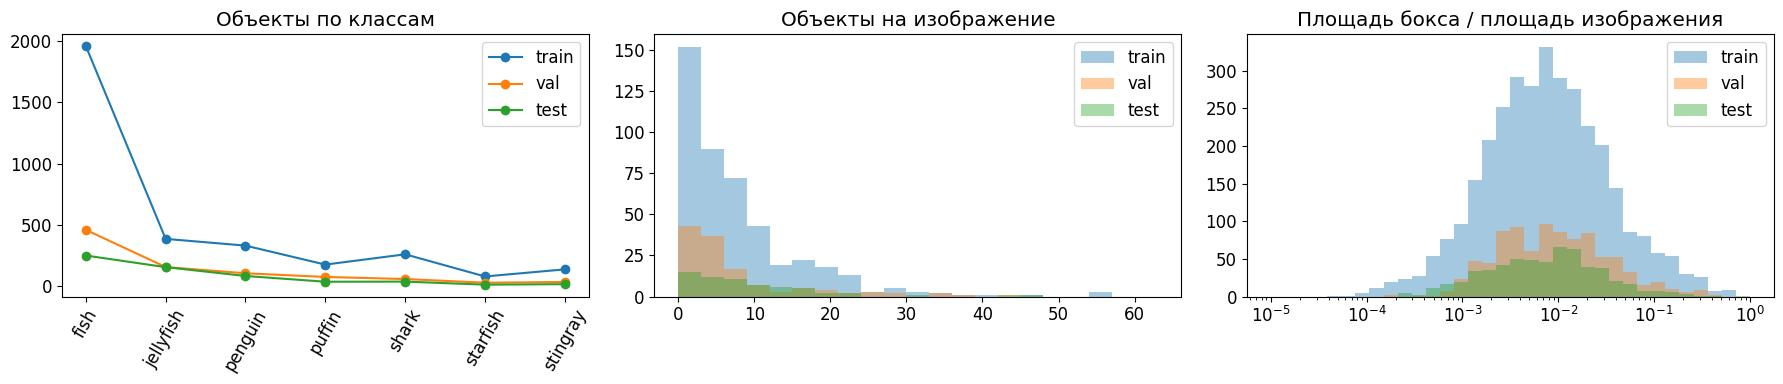

Объекты: {'train': {'fish': 1961, 'jellyfish': 385, 'penguin': 330, 'puffin': 175, 'shark': 259, 'starfish': 78, 'stingray': 136}, 'val': {'fish': 459, 'jellyfish': 155, 'penguin': 104, 'puffin': 74, 'shark': 57, 'starfish': 27, 'stingray': 33}, 'test': {'fish': 249, 'jellyfish': 154, 'penguin': 82, 'puffin': 35, 'shark': 36, 'starfish': 11, 'stingray': 15}}
Плотность: {'train': {'mean': 7.419642857142857, 'median': 4.0, 'max': 56, 'empty': 1}, 'val': {'mean': 7.15748031496063, 'median': 4.0, 'max': 44, 'empty': 0}, 'test': {'mean': 9.238095238095237, 'median': 8.0, 'max': 45, 'empty': 0}}
Размеры: {'train': {'median_area': 0.007312138564884663, 'area_below_1pct': 0.589049338146811}, 'val': {'median_area': 0.008656819351017475, 'area_below_1pct': 0.5533553355335533}, 'test': {'median_area': 0.007928213104605675, 'area_below_1pct': 0.570446735395189}}


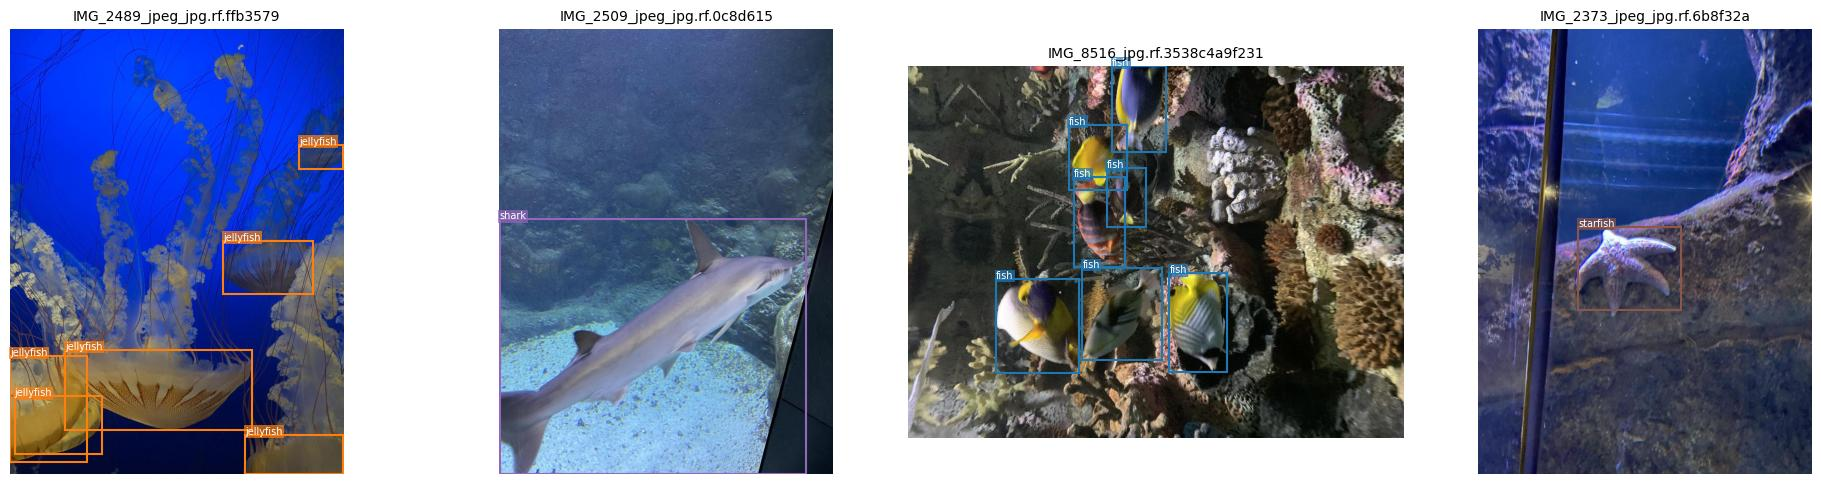

In [11]:
# ваш код
CLASS_COUNTS = {}
DENSITY = {}
SIZE_STATS = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for split, recs in records.items():
    counts = Counter(int(c) for r in recs for c in r['labels'])
    CLASS_COUNTS[split] = {name: counts[i] for i, name in enumerate(CLASSES)}
    number = np.array([len(r['labels']) for r in recs])
    DENSITY[split] = dict(mean=float(number.mean()), median=float(np.median(number)), max=int(number.max()), empty=int((number == 0).sum()))
    relative_area = np.concatenate([(r['boxes'][:, 2] - r['boxes'][:, 0]) * (r['boxes'][:, 3] - r['boxes'][:, 1]) / (r['width'] * r['height']) for r in recs])
    SIZE_STATS[split] = dict(median_area=float(np.median(relative_area)), area_below_1pct=float((relative_area < .01).mean()))
    axes[0].plot(CLASSES, [counts[i] for i in range(len(CLASSES))], marker='o', label=split)
    axes[1].hist(number, bins=np.arange(0, 65, 3), alpha=.4, label=split)
    axes[2].hist(relative_area, bins=np.geomspace(1e-5, 1, 35), alpha=.4, label=split)
axes[0].tick_params(axis='x', rotation=60)
axes[0].set_title('Объекты по классам')
axes[1].set_title('Объекты на изображение')
axes[2].set_title('Площадь бокса / площадь изображения')
axes[2].set_xscale('log')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
print('Объекты:', CLASS_COUNTS)
print('Плотность:', DENSITY)
print('Размеры:', SIZE_STATS)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, r in zip(axes, [records['train'][i] for i in (0, 30, 100, 200)]):
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, title=Path(r['image']).name[:28])
plt.tight_layout()
plt.show()

Ответ

Я взяла исходное разбиение Aquarium Combined v2: 448 фото в train, 127 в val и 63 в test. Лицензия CC BY 4.0. На фото размечены рыбы, медузы, пингвины, тупики, акулы, морские звёзды и скаты.

Рыб в train гораздо больше, чем морских звёзд: 1961 бокс против 78. Больше половины боксов занимают меньше 1% кадра. В среднем в train около семи объектов на фото, а на одном кадре их 56. У медуз на примерах сложно понять, где провести границу бокса из-за щупалец. Из test я удалила два бокса акул с нулевой площадью.


## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    # ваш код
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)
    if width <= 0 or height <= 0 or len(boxes) != len(labels):
        raise ValueError('Некорректные размеры')
    normalized = np.column_stack(((boxes[:, 0] + boxes[:, 2]) / (2 * width),
                                  (boxes[:, 1] + boxes[:, 3]) / (2 * height),
                                  (boxes[:, 2] - boxes[:, 0]) / width,
                                  (boxes[:, 3] - boxes[:, 1]) / height))
    return ''.join(f'{int(label)} ' + ' '.join(f'{v:.6f}' for v in row) + '\n' for label, row in zip(labels, normalized))


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    # ваш код
    rows = [line.split() for line in text.splitlines() if line.strip()]
    if any(len(row) != 5 for row in rows):
        raise ValueError('Ожидаются class cx cy w h')
    if not rows:
        return np.empty((0, 4), dtype=np.float32), np.empty(0, dtype=np.int64)
    values = np.asarray(rows, dtype=float)
    if not np.isfinite(values).all() or not np.equal(values[:, 0], np.floor(values[:, 0])).all():
        raise ValueError('Некорректные значения YOLO')
    cx, cy, w, h = values[:, 1:].T
    boxes = np.column_stack(((cx - w / 2) * width, (cy - h / 2) * height,
                             (cx + w / 2) * width, (cy + h / 2) * height))
    return boxes.astype(np.float32), values[:, 0].astype(np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo_exports' / RUN_ID


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    # ваш код
    image_dir = YOLO_ROOT / 'images' / split
    label_dir = YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    seen = set()
    for r in recs:
        source = Path(r['image'])
        if source.stem in seen:
            raise ValueError('Совпали имена изображений: ' + source.stem)
        seen.add(source.stem)
        shutil.copy2(source, image_dir / source.name)
        (label_dir / (source.stem + '.txt')).write_text(to_yolo(r['boxes'], r['labels'], r['width'], r['height']), encoding='utf-8')


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
assert YOLO_ROOT.resolve().is_relative_to((Path.cwd() / 'data').resolve())
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: C:/Users/ninak/PycharmProjects/dl-hw2/data/yolo_exports/9477498e6f2548c8ac5e907d3bfb1bf8
train: images/train
val: images/val
test: images/test
names:
  0: fish
  1: jellyfish
  2: penguin
  3: puffin
  4: shark
  5: starfish
  6: stingray



Проверены все TXT; максимальная ошибка, px: 0.00079345703125


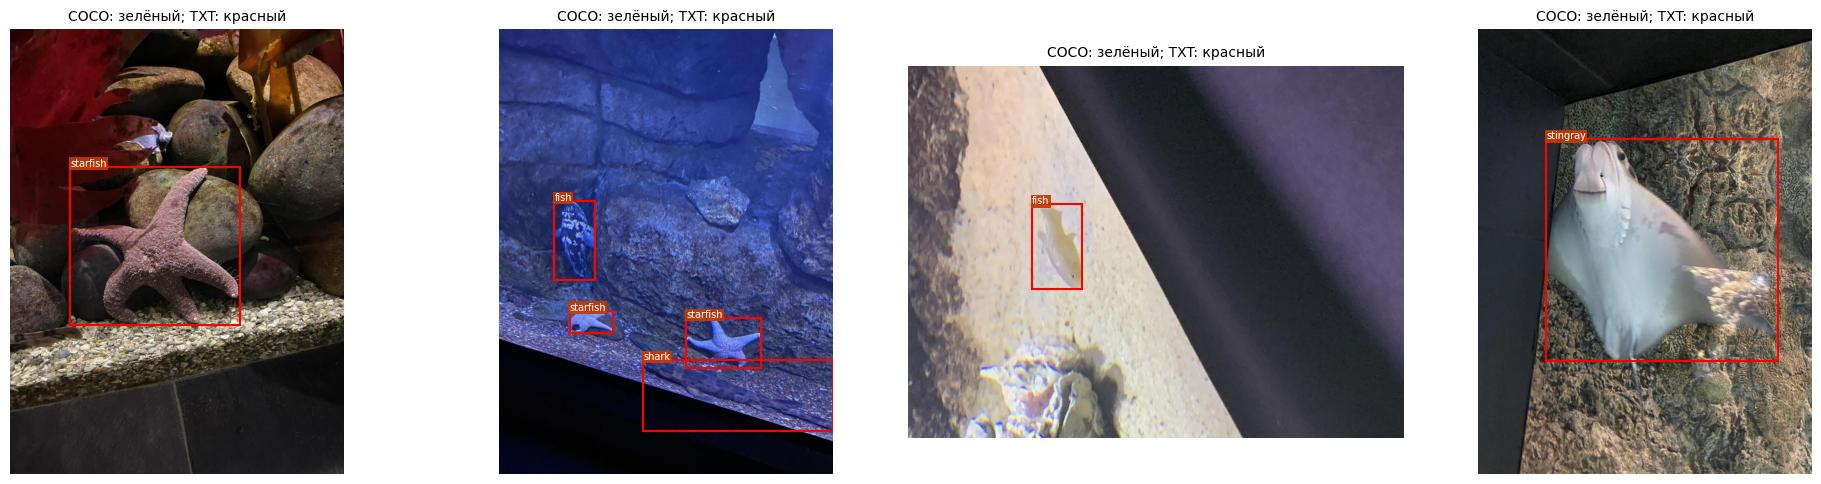

In [15]:
# ваш код
config = yaml.safe_load(DATA_YAML.read_text())
assert config['names'] == dict(enumerate(CLASSES))
max_roundtrip_error = 0.
for split, recs in splits.items():
    assert (Path(config['path']) / config[split]).is_dir()
    for r in recs:
        txt = YOLO_ROOT / 'labels' / split / (Path(r['image']).stem + '.txt')
        boxes, labels = from_yolo(txt.read_text(), r['width'], r['height'])
        assert np.array_equal(labels, r['labels'])
        assert np.allclose(boxes, r['boxes'], atol=.002)
        if len(boxes):
            max_roundtrip_error = max(max_roundtrip_error, float(np.abs(boxes - r['boxes']).max()))
print('Проверены все TXT; максимальная ошибка, px:', max_roundtrip_error)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, r in zip(axes, records['val'][:4]):
    boxes, labels = from_yolo((YOLO_ROOT / 'labels' / 'val' / (Path(r['image']).stem + '.txt')).read_text(), r['width'], r['height'])
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='lime', linestyle='--')
    draw_boxes(ax, None, boxes, labels, CLASSES, color='red', title='COCO: зелёный; TXT: красный')
plt.tight_layout()
plt.show()

Ответ

Я прочитала обратно все записанные TXT. Классы совпали, а координаты отличались максимум на 0,000793 пикселя из-за округления. Если при записи и чтении дважды поменять местами оси, исходные числа восстановятся и тест пройдёт. Поэтому я ещё наложила боксы на четыре фотографии. Так видно, если рамки смещены или стоят не на тех объектах.


---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

Прямые соответствия: {} mAP50: 0.0
Реальные COCO-классы при conf >= .25: Counter({'bird': 26, 'person': 12, 'bear': 2, 'kite': 2, 'sports ball': 1, 'cat': 1, 'orange': 1, 'umbrella': 1})


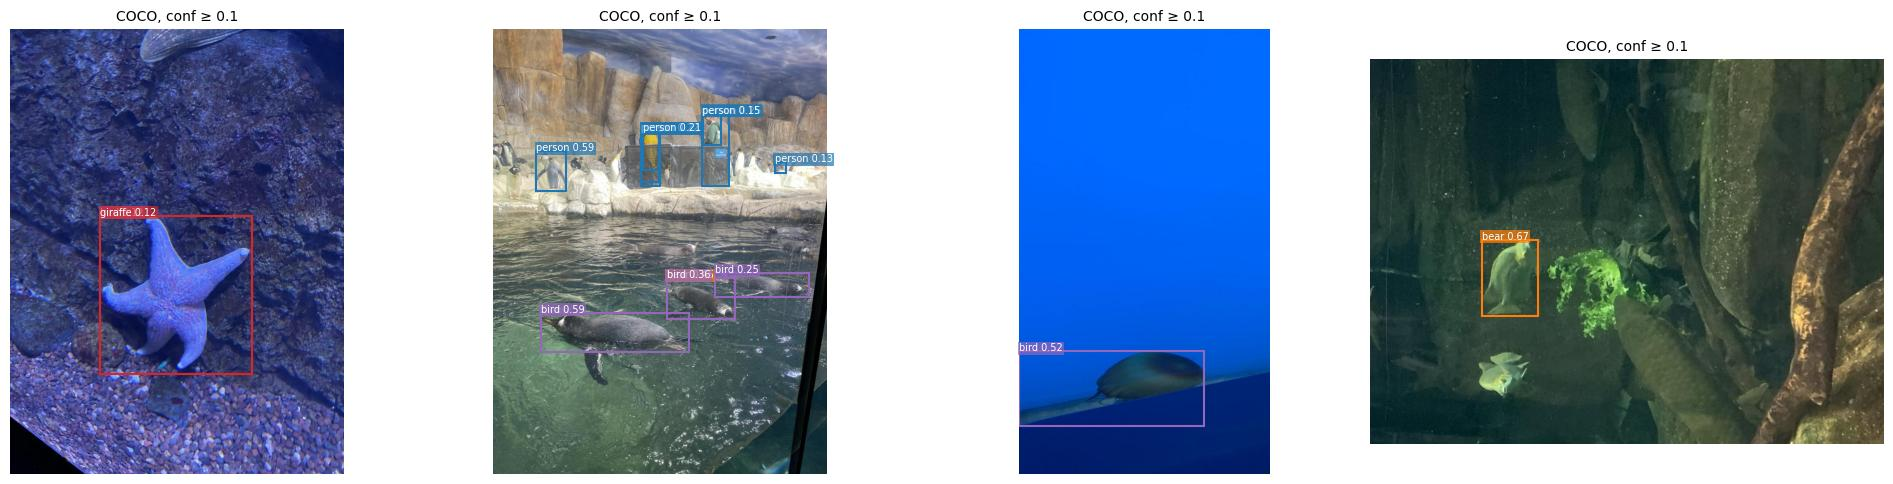

In [16]:
# ваш код
start = time.perf_counter()
coco_preds = predict_records(model_coco, records[FINAL_SPLIT])
RUN_TIMES['coco'] = time.perf_counter() - start
direct_matches = {i: CLASSES.index(name) for i, name in model_coco.names.items() if name in CLASSES}
mapped_preds = []
for p in coco_preds:
    keep = np.array([int(c) in direct_matches for c in p['labels']], dtype=bool)
    mapped_preds.append(dict(boxes=p['boxes'][keep], scores=p['scores'][keep],
                             labels=np.array([direct_matches[int(c)] for c in p['labels'][keep]], dtype=np.int64)))
coco_map50, coco_aps = evaluate_map50(mapped_preds, records[FINAL_SPLIT], len(CLASSES))
print('Прямые соответствия:', direct_matches, 'mAP50:', coco_map50)
print('Реальные COCO-классы при conf >= .25:', Counter(model_coco.names[int(c)] for p in coco_preds for c, score in zip(p['labels'], p['scores']) if score >= .25))
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, r, p in zip(axes, records[FINAL_SPLIT][:4], coco_preds[:4]):
    keep = p['scores'] >= .1
    draw_boxes(ax, Image.open(r['image']), p['boxes'][keep], p['labels'][keep], model_coco.names, p['scores'][keep], title='COCO, conf ≥ 0.1')
plt.tight_layout()
plt.show()

In [17]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    # ваш код
    with Image.open(image_path) as image:
        width, height = image.size
    boxes, labels, scores = [], [], []
    for c, (bw, bh) in enumerate(HEURISTIC_SIZES):
        for cy in GRID:
            for cx in GRID:
                boxes.append([max(0, (cx - bw / 2) * width), max(0, (cy - bh / 2) * height),
                              min(width, (cx + bw / 2) * width), min(height, (cy + bh / 2) * height)])
                labels.append(c)
                scores.append(float(HEURISTIC_PRIORS[c]))
    return dict(boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4), labels=np.asarray(labels, dtype=np.int64), scores=np.asarray(scores))

In [18]:
# ваш код: параметры эвристики, если нужны (подбирать по train, не по val)
GRID = np.array([1 / 6, .5, 5 / 6])
HEURISTIC_SIZES = []
HEURISTIC_PRIORS = []
for c in range(len(CLASSES)):
    sizes = [(r['boxes'][r['labels'] == c, 2:] - r['boxes'][r['labels'] == c, :2]) / [r['width'], r['height']] for r in train_recs]
    sizes = np.concatenate(sizes)
    HEURISTIC_SIZES.append(np.median(sizes, axis=0))
    HEURISTIC_PRIORS.append(len(sizes) / sum(len(r['labels']) for r in train_recs))
print('Размеры:', np.array(HEURISTIC_SIZES), 'частоты:', HEURISTIC_PRIORS)


Размеры: [[   0.089844      0.0625]
 [    0.12674    0.086914]
 [   0.052734    0.055664]
 [   0.092448    0.091797]
 [    0.20182      0.1084]
 [    0.19401     0.17871]
 [    0.22786       0.125]] частоты: [0.5899518652226233, 0.11582430806257521, 0.09927797833935018, 0.05264741275571601, 0.07791817087845969, 0.023465703971119134, 0.04091456077015644]


In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.00022906676155401299,
 'heuristic_ap50_per_class': {'fish': 4.183400267737616e-05,
  'jellyfish': 0.0001610731041110788,
  'penguin': 0.0,
  'puffin': 0.0,
  'shark': 0.0,
  'starfish': 0.0005347593582887701,
  'stingray': 0.0008658008658008658}}

Ответ

У исходной модели mAP50 на test получился нулевым. Среди классов COCO нет прямых соответствий классам Aquarium. Например, модель может поставить метку bird, но по ней нельзя отличить пингвина от тупика.

Для простого бейзлайна я расставила типовые боксы по сетке. На test вышло 0,000229 mAP50. Чуть лучше сетка сработала на скатах и морских звёздах: их типовые боксы крупнее, и совпасть с ними случайно проще. Для пингвинов, тупиков и акул AP50 остался нулевым.


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    target = (RUNS / name).resolve()
    assert target.parent == RUNS.resolve() and target.is_relative_to(Path.cwd().resolve())
    if target.exists():
        shutil.rmtree(target)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
# ваш код
TRAIN_ARGS = dict(epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, optimizer='AdamW', lr0=.001, lrf=.01,
                  warmup_bias_lr=0.,
                  momentum=.9, weight_decay=.0005, warmup_epochs=1 if FAST_MODE else 3,
                  patience=EPOCHS, seed=SEED, deterministic=True, val=True, amp=True,
                  hsv_h=.015, hsv_s=.5, hsv_v=.4, degrees=0., translate=.1, scale=.5,
                  fliplr=.5, flipud=0., mosaic=1., mixup=0., close_mosaic=0 if FAST_MODE else 10,
                  cache=False, plots=True, save=True)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

New https://pypi.org/project/ultralytics/8.4.218 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.0  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data\yolo_exports\9477498e6f2548c8ac5e907d3bfb1bf8\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.9, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=60, perspective=0.0, plots=True, pose=12.0, pretrained=True, profile=False, project

Overriding model.yaml nc=80 with nc=7



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (2,149 outputs left out)

                   all        127        909      0.747      0.675      0.717      0.439


Speed: 0.1ms preprocess, 1.2ms inference, 0.0ms loss, 0.1ms postprocess per image


Results saved to C:\Users\ninak\PycharmProjects\dl-hw2\runs_hw2\full\9477498e6f2548c8ac5e907d3bfb1bf8\finetune


обучение: 946 s на NVIDIA GeForce RTX 5060 Laptop GPU, каталог C:\Users\ninak\PycharmProjects\dl-hw2\runs_hw2\full\9477498e6f2548c8ac5e907d3bfb1bf8\finetune


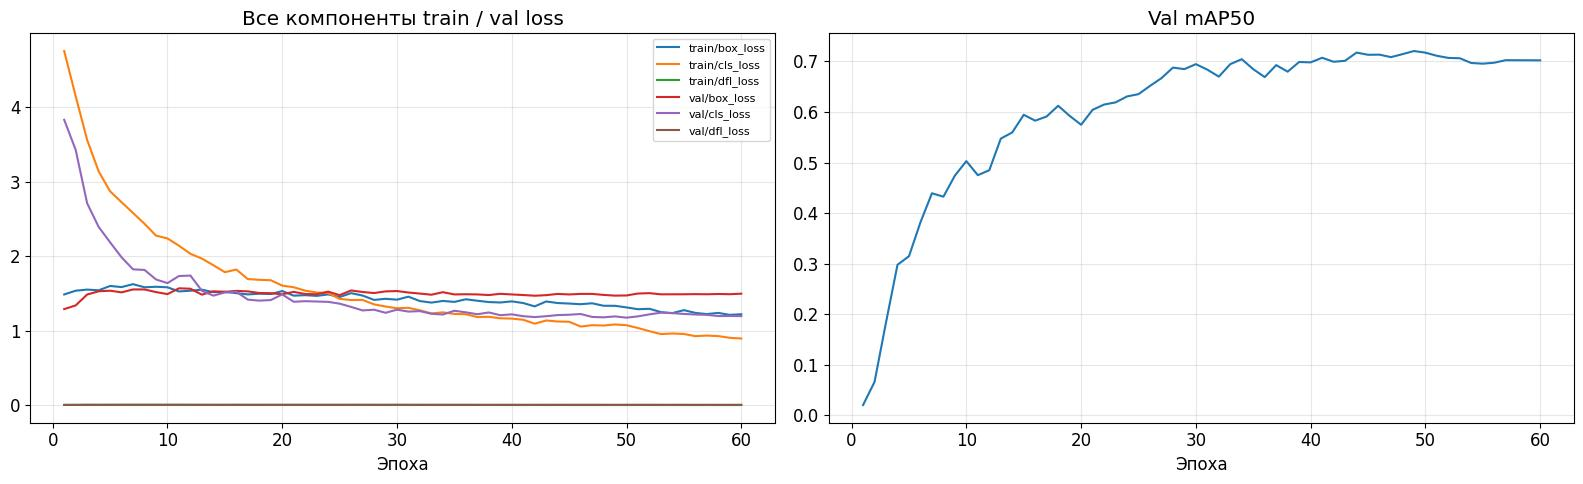

Компоненты: ['train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss']
Первая / последняя эпоха: {'train/box_loss': [1.48793, 1.2226], 'train/cls_loss': [4.75244, 0.89738], 'train/dfl_loss': [0.00656, 0.00537], 'val/box_loss': [1.29177, 1.49852], 'val/cls_loss': [3.83008, 1.19777], 'val/dfl_loss': [0.00689, 0.00805]}


In [22]:
# ваш код
history = read_results(run_dir)
loss_columns = [k for k in history if k.startswith(('train/', 'val/')) and 'loss' in k]
assert len(history['epoch']) == TRAIN_ARGS['epochs']
assert all(np.isfinite(history[k]).all() for k in loss_columns), 'Обнаружены NaN/Inf в loss'
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for key in loss_columns:
    axes[0].plot(history['epoch'], history[key], label=key)
axes[0].legend(fontsize=8)
axes[0].set_title('Все компоненты train / val loss')
axes[1].plot(history['epoch'], history['metrics/mAP50(B)'])
axes[1].set_title('Val mAP50')
for ax in axes:
    ax.set_xlabel('Эпоха')
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()
print('Компоненты:', loss_columns)
print('Первая / последняя эпоха:', {k: [float(history[k][0]), float(history[k][-1])] for k in loss_columns})

Ответ

Я выбрала размер 640 ради мелких объектов. Batch 16 с AMP поместился в память карты. Для дообучения взяла AdamW с начальной скоростью 0,001 и прогревом на трёх эпохах. Оставила 60 эпох и patience 60, чтобы сравнить два разрешения при одинаковом бюджете. Меняла цвета и масштаб кадров, а на последних десяти эпохах отключила mosaic.

Прогон занял 946 с. На train ошибка боксов снизилась с 1,488 до 1,223, а на val выросла с 1,292 до 1,499. Похоже, модель стала лучше подгонять боксы на train, хотя ошибка классов на val продолжала снижаться. Лучшие веса сохранились на 50-й эпохе. К концу mAP50 держался около 0,70, поэтому продлевать именно этот прогон я бы не стала.


## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.0  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


YOLO26n summary (fused): 122 layers, 2,376,201 parameters, 0 gradients, 5.2 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 1050.1269.4 MB/s, size: 97.4 KB)


val: Scanning C:\Users\ninak\PycharmProjects\dl-hw2\data\yolo_exports\9477498e6f2548c8ac5e907d3bfb1bf8\labels\val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 12% ━─────────── 1/8 1.5it/s 0.2s<4.6s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 2/8 2.0it/s 0.5s<2.9s

... (19 outputs left out)

Speed: 0.2ms preprocess, 2.0ms inference, 0.0ms loss, 0.1ms postprocess per image


Results saved to C:\Users\ninak\PycharmProjects\dl-hw2\runs_hw2\full\9477498e6f2548c8ac5e907d3bfb1bf8\evaluate_test


test {
  "map50": 0.7470406643380751,
  "map50_95": 0.45844435172505477,
  "precision": 0.7721441310483268,
  "recall": 0.6801040916754123,
  "per_class": {
    "fish": {
      "map50": 0.6976130620401227,
      "map50_95": 0.4084658701701461,
      "precision": 0.7481813042595341,
      "recall": 0.6506024096385542
    },
    "jellyfish": {
      "map50": 0.8243857530873544,
      "map50_95": 0.5068327280726005,
      "precision": 0.7711124326117503,
      "recall": 0.7792207792207793
    },
    "penguin": {
      "map50": 0.726492480425653,
      "map50_95": 0.3126997149296583,
      "precision": 0.8200186947855866,
      "recall": 0.524390243902439
    },
    "puffin": {
      "map50": 0.3885749714888972,
      "map50_95": 0.16922251879852718,
      "precision": 0.684188161983407,
      "recall": 0.34285714285714286
    },
    "shark": {
      "map50": 0.8039781235842389,
      "map50_95": 0.5667772436123125,
      "precision": 0.8367588436848251,
      "recall": 0.7121429145938187


Собственный mAP50: 0.7440691945236632 разница с model.val: -0.0029714698144119867


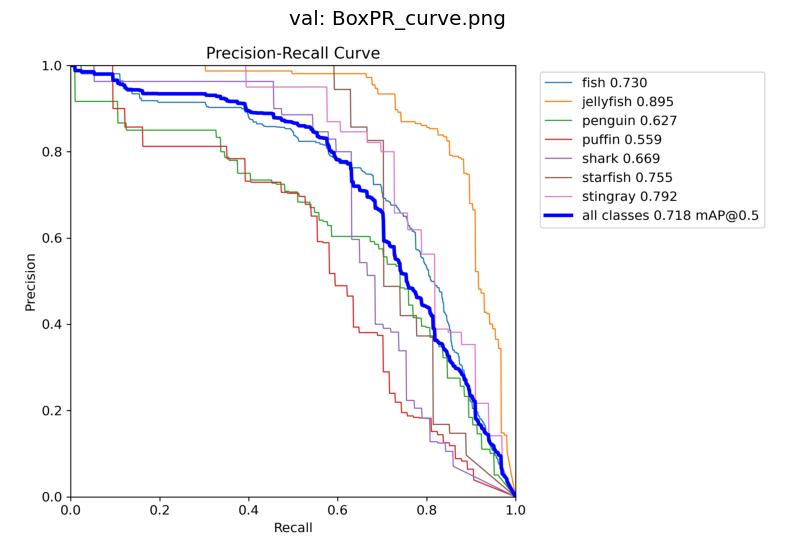

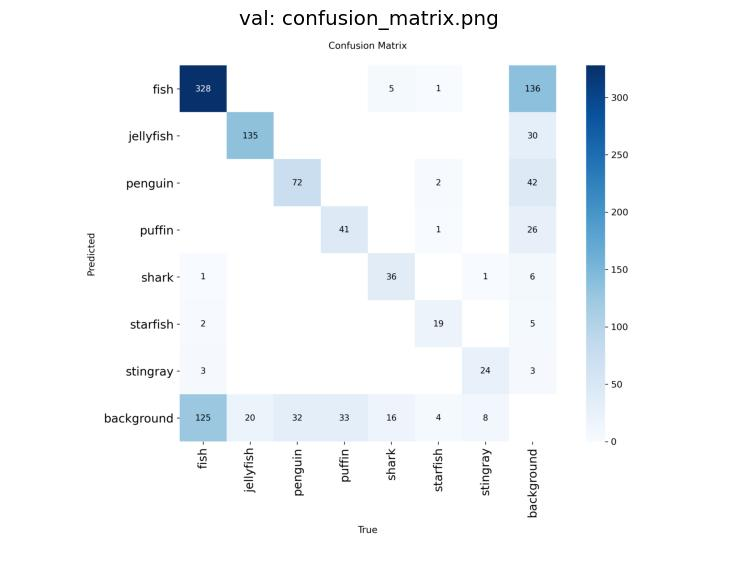

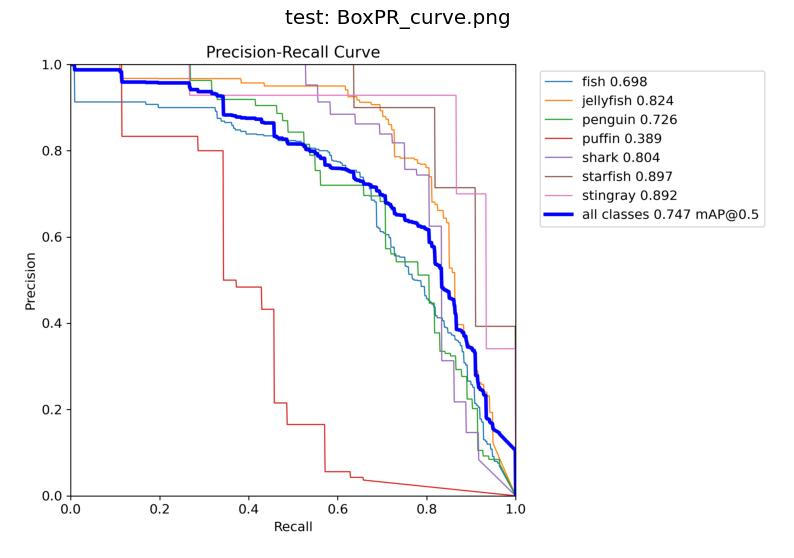

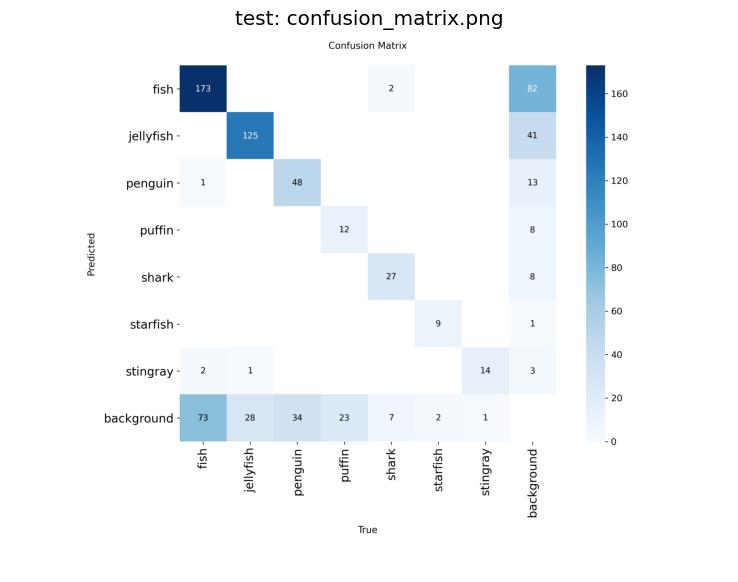

In [24]:
# ваш код
def summarize_metrics(result):
    per_class = {}
    for j, c in enumerate(result.box.ap_class_index):
        per_class[CLASSES[int(c)]] = dict(map50=float(result.box.ap50[j]), map50_95=float(result.box.ap[j]),
                                        precision=float(result.box.p[j]), recall=float(result.box.r[j]))
    return dict(map50=float(result.box.map50), map50_95=float(result.box.map), precision=float(result.box.mp),
                recall=float(result.box.mr), per_class=per_class)

VAL_RESULTS = {}
VAL_METRICS = {}
start = time.perf_counter()
for split in ('val', 'test'):
    result = val_metrics(best, split, 'evaluate_' + split, plots=True, conf=.001, iou=.7)
    VAL_RESULTS[split] = result
    VAL_METRICS[split] = summarize_metrics(result)
    print(split, json.dumps(VAL_METRICS[split], ensure_ascii=False, indent=2))
RUN_TIMES['evaluation'] = time.perf_counter() - start
FINAL = dict(split=FINAL_SPLIT, **VAL_METRICS[FINAL_SPLIT])
final_preds = predict_records(best, records[FINAL_SPLIT], conf=.001, iou=.7, rect=True)
manual_map50, manual_aps = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
FINAL['manual_map50'] = manual_map50
FINAL['manual_ap50_per_class'] = dict(zip(CLASSES, manual_aps))
print('Собственный mAP50:', manual_map50, 'разница с model.val:', manual_map50 - FINAL['map50'])
for split in ('val', 'test'):
    for filename in ('BoxPR_curve.png', 'confusion_matrix.png'):
        image = Path(VAL_RESULTS[split].save_dir) / filename
        if image.exists():
            fig, ax = plt.subplots(figsize=(10, 7))
            ax.imshow(Image.open(image))
            ax.axis('off')
            ax.set_title(split + ': ' + filename)
            plt.show()

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'split': 'test',
 'map50': 0.747,
 'map50_95': 0.4584,
 'precision': 0.7721,
 'recall': 0.6801,
 'manual_map50': 0.7441,
 'manual_ap50_per_class': {'fish': 0.6988692592337553,
  'jellyfish': 0.8320540568648982,
  'penguin': 0.705157006416556,
  'puffin': 0.4273322743322354,
  'shark': 0.8015978407510527,
  'starfish': 0.8568181818181818,
  'stingray': 0.8866557422489626}}

Ответ

На val я получила mAP50 0,7183 и mAP50-95 0,4410. На test вышло 0,7470 и 0,4584. Хуже всего на test модель находила тупиков (AP50 0,3886). На примерах мелкие птицы сливаются с камнями. В train у этого класса 175 боксов, так что примеров заметно меньше, чем у рыб.

В матрице ошибок строка background показывает пропуски, а столбец background показывает лишние предсказания. При более высоком IoU даже найденный объект может не засчитаться, если рамка неточная. Поэтому mAP50-95 ниже mAP50.

Мой расчёт mAP50 на test дал 0,7441. У Ultralytics получилось 0,7470. Разница около 0,3 процентного пункта может объясняться тем, как сопоставляются рамки и считается площадь под PR-кривой.


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    # ваш код
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    intersection_wh = np.maximum(0, np.minimum(a[:, None, 2:], b[None, :, 2:]) - np.maximum(a[:, None, :2], b[None, :, :2]))
    intersection = intersection_wh.prod(axis=2)
    area_a = np.maximum(0, a[:, 2:] - a[:, :2]).prod(axis=1)
    area_b = np.maximum(0, b[:, 2:] - b[:, :2]).prod(axis=1)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    # ваш код
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    categories = np.full(len(pred['boxes']), 'background', dtype=object)
    found = np.zeros(len(gt['boxes']), dtype=bool)
    explained = np.zeros(len(gt['boxes']), dtype=bool)
    gt_labels = np.asarray(gt['labels'])
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same = gt_labels == pred['labels'][i]
        candidates = np.flatnonzero(same & ~found & (ious[i] >= iou_hit))
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = 'tp'
            found[j] = True
            explained[j] = True
            continue
        candidates = np.flatnonzero(~same & (ious[i] >= iou_hit))
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = 'class'
            explained[j] = True
            continue
        candidates = np.flatnonzero(same & ~found & (ious[i] >= iou_loc) & (ious[i] < iou_hit))
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = 'localization'
            explained[j] = True
    return categories.tolist(), np.flatnonzero(~explained).tolist()

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


Категории: {'tp': 636, 'class': 20, 'localization': 43, 'background': 222, 'missed': 227}
Доли среди предсказаний и необъяснённых GT: {'tp': 0.554006968641115, 'class': 0.017421602787456445, 'localization': 0.037456445993031356, 'background': 0.19337979094076654, 'missed': 0.19773519163763068}
Разбивка по предсказанному классу, для missed по GT: {
  "fish": {
    "tp": 328,
    "class": 9,
    "localization": 15,
    "background": 126,
    "missed": 116
  },
  "jellyfish": {
    "tp": 134,
    "class": 0,
    "localization": 5,
    "background": 33,
    "missed": 16
  },
  "penguin": {
    "tp": 65,
    "class": 3,
    "localization": 14,
    "background": 30,
    "missed": 32
  },
  "puffin": {
    "tp": 35,
    "class": 1,
    "localization": 7,
    "background": 18,
    "missed": 32
  },
  "shark": {
    "tp": 31,
    "class": 2,
    "localization": 2,
    "background": 6,
    "missed": 19
  },
  "starfish": {
    "tp": 19,
    "class": 1,
    "localization": 0,
    "background": 6,

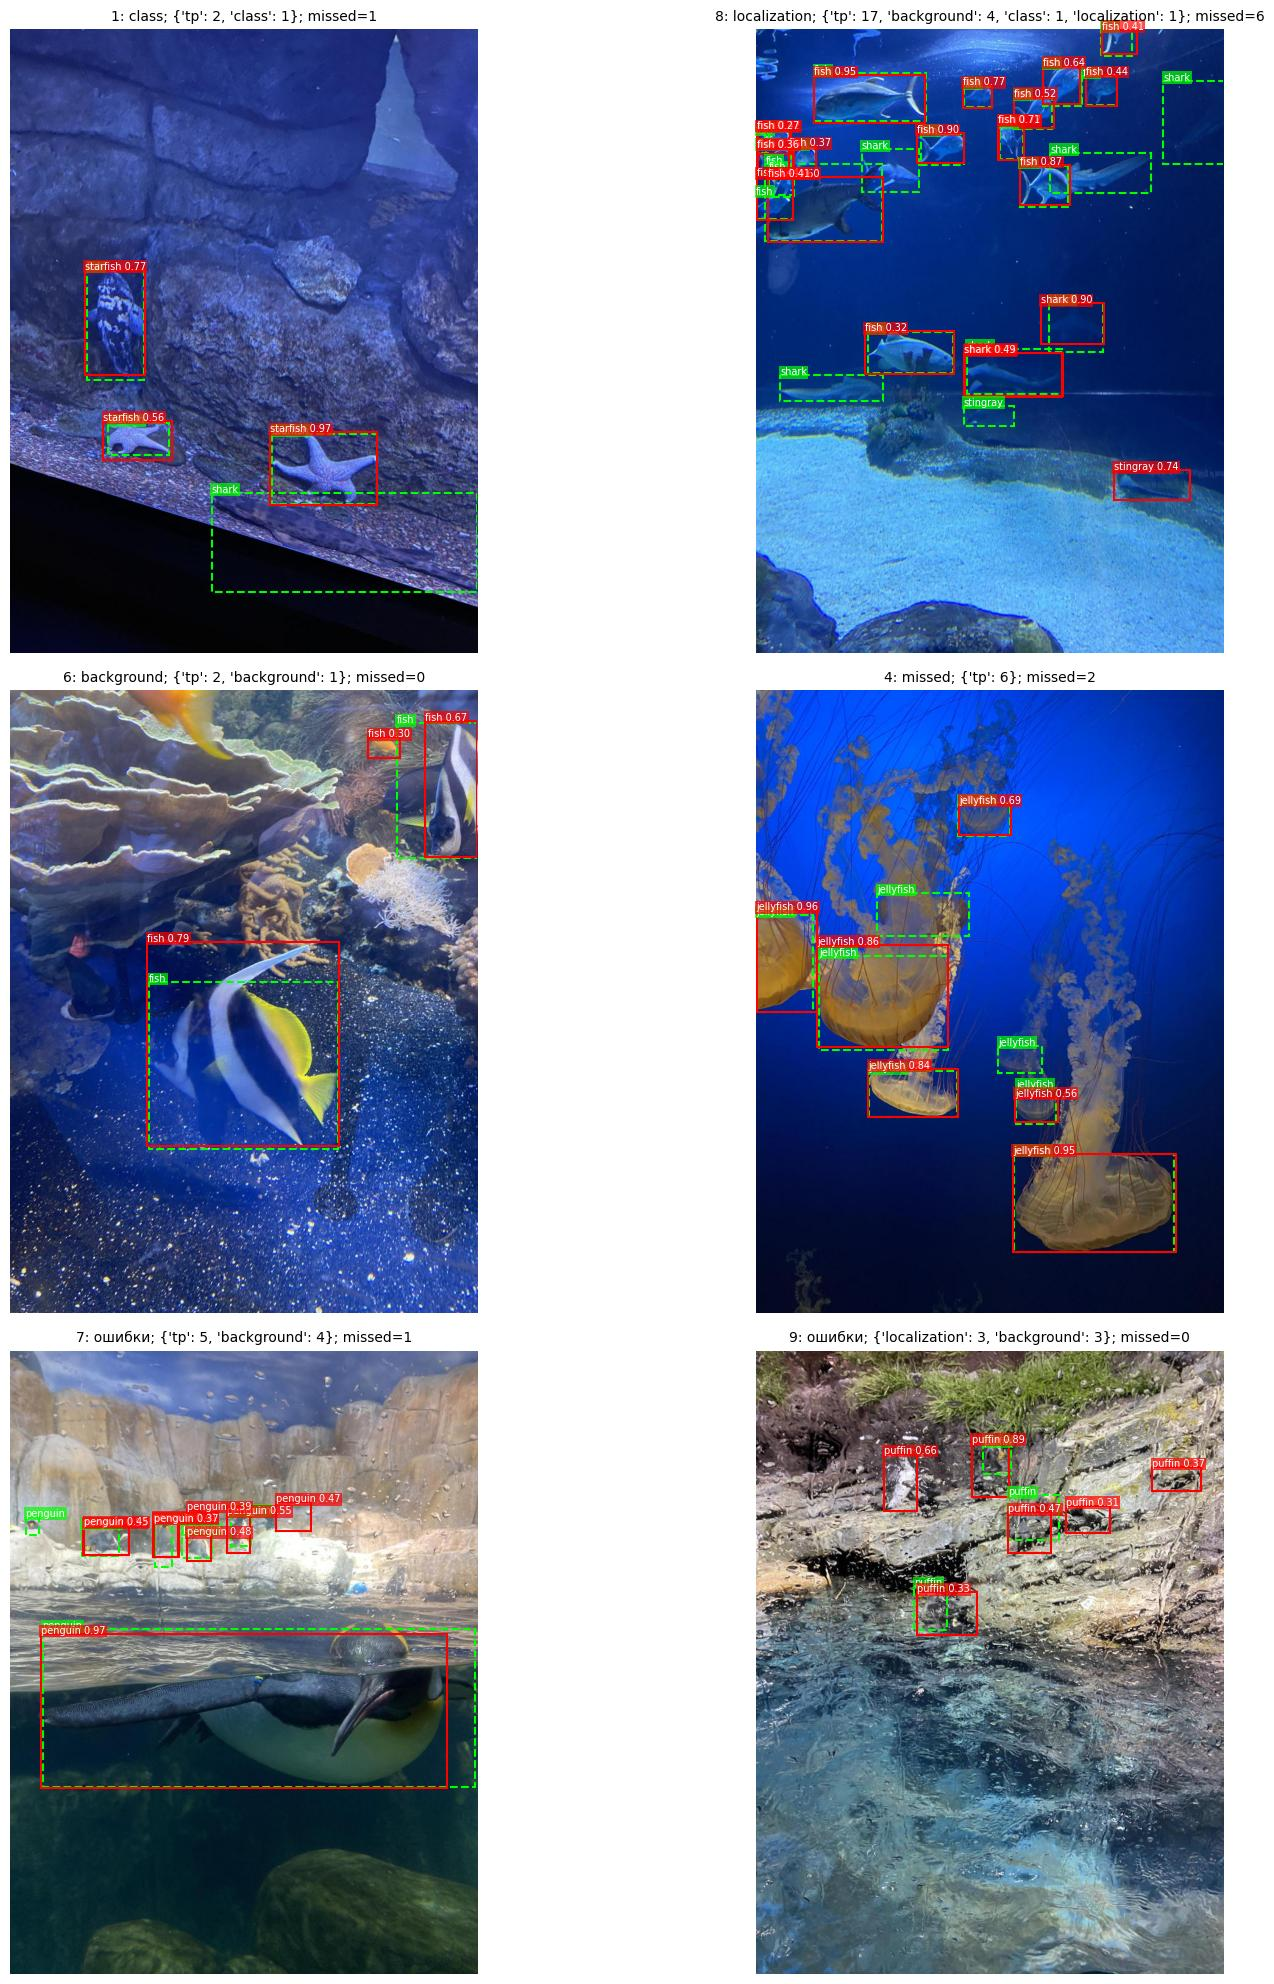

In [28]:
# ваш код
error_preds = predict_records(best, records['val'], conf=CONF_ERRORS, iou=.7)
ERRORS = dict.fromkeys(ERROR_TYPES, 0)
ERRORS_BY_CLASS = {name: dict.fromkeys(ERROR_TYPES, 0) for name in CLASSES}
categorized = []
for r, p in zip(records['val'], error_preds):
    cats, missed = categorize_predictions(p, r)
    categorized.append((cats, missed))
    for label, cat in zip(p['labels'], cats):
        ERRORS[cat] += 1
        ERRORS_BY_CLASS[CLASSES[int(label)]][cat] += 1
    ERRORS['missed'] += len(missed)
    for j in missed:
        ERRORS_BY_CLASS[CLASSES[int(r['labels'][j])]]['missed'] += 1
ERROR_SHARES = {k: v / max(1, sum(ERRORS.values())) for k, v in ERRORS.items()}
print('Категории:', ERRORS)
print('Доли среди предсказаний и необъяснённых GT:', ERROR_SHARES)
print('Разбивка по предсказанному классу, для missed по GT:', json.dumps(ERRORS_BY_CLASS, ensure_ascii=False, indent=2))
examples, seen_images = [], set()
for wanted in ('class', 'localization', 'background', 'missed'):
    for i, (cats, missed) in enumerate(categorized):
        if i not in seen_images and (wanted in cats or (wanted == 'missed' and missed)):
            examples.append((i, wanted))
            seen_images.add(i)
            break
for i, (cats, missed) in enumerate(categorized):
    if len(examples) >= 6:
        break
    if i not in seen_images and (any(c != 'tp' for c in cats) or missed):
        examples.append((i, 'ошибки'))
        seen_images.add(i)
assert len(examples) >= 5
fig, axes = plt.subplots(3, 2, figsize=(18, 20))
for ax, (i, wanted) in zip(axes.flat, examples):
    r, p = records['val'][i], error_preds[i]
    cats, missed = categorized[i]
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='lime', linestyle='--')
    draw_boxes(ax, None, p['boxes'], p['labels'], CLASSES, p['scores'], color='red', title=f'{i}: {wanted}; {dict(Counter(cats))}; missed={len(missed)}')
plt.tight_layout()
plt.show()

Ответ

При conf 0,25 на val я насчитала 227 пропусков и 222 лишних бокса. Рыб пропущено больше всего: 116 из 459. На кадре №4 модель пропустила часть медуз, которые перекрываются. На кадре №1 ошибка оказалась в разметке: морская звезда подписана как рыба.

Я бы добавила больше кадров с мелкими объектами в плотных группах и проверила разметку на таких кадрах. Снижение conf тоже помогает найти больше объектов, но в бонусе 6.5 видно, что при этом растёт число ложных детекций.


## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
# ваш код
ablation_args = dict(TRAIN_ARGS, imgsz=640 if FAST_MODE else 320)
assert {k for k in TRAIN_ARGS if TRAIN_ARGS[k] != ablation_args[k]} == {'imgsz'}
ablation_model, RUN_TIMES['ablation_train'], ablation_dir = train_yolo('ablation_resolution', **ablation_args)
ablation_best = YOLO(ablation_dir / 'weights' / 'best.pt')
ablation_val = ablation_best.val(data=str(DATA_YAML), split='val', imgsz=ablation_args['imgsz'], batch=BATCH,
                               device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name='ablation_val',
                               exist_ok=True, plots=False, conf=.001, iou=.7, verbose=False)
ABLATION = dict(parameter='imgsz', split='val', seed=SEED, weights_sha256=MODEL_INFO['sha256'],
                main=dict(value=IMGSZ, **VAL_METRICS['val'], train_time_sec=RUN_TIMES['train']),
                changed=dict(value=ablation_args['imgsz'], **summarize_metrics(ablation_val), train_time_sec=RUN_TIMES['ablation_train']))
print(json.dumps(ABLATION, ensure_ascii=False, indent=2))
del ablation_model, ablation_best
import gc
gc.collect()
torch.cuda.empty_cache()

New https://pypi.org/project/ultralytics/8.4.218 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.0  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data\yolo_exports\9477498e6f2548c8ac5e907d3bfb1bf8\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=320, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.9, mosaic=1.0, multi_scale=0.0, name=ablation_resolution, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=60, perspective=0.0, plots=True, pose=12.0, pretrained=True, profile=Fal

Overriding model.yaml nc=80 with nc=7



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (2,158 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 8.6it/s 0.9s

                   all        127        909      0.632      0.577      0.618      0.349


Speed: 0.3ms preprocess, 2.3ms inference, 0.0ms loss, 0.1ms postprocess per image


{
  "parameter": "imgsz",
  "split": "val",
  "seed": 0,
  "weights_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef",
  "main": {
    "value": 640,
    "map50": 0.7182912018760641,
    "map50_95": 0.44096729664567125,
    "precision": 0.7354378801519427,
    "recall": 0.6752966916415833,
    "per_class": {
      "fish": {
        "map50": 0.7303120711441307,
        "map50_95": 0.4086592185480814,
        "precision": 0.7226157154279441,
        "recall": 0.6924256507743433
      },
      "jellyfish": {
        "map50": 0.8954088091545226,
        "map50_95": 0.5110956884326117,
        "precision": 0.8244721524772498,
        "recall": 0.8451612903225807
      },
      "penguin": {
        "map50": 0.6273604625770509,
        "map50_95": 0.28660756328040393,
        "precision": 0.6013701139821227,
        "recall": 0.6382712175965293
      },
      "puffin": {
        "map50": 0.558802715822371,
        "map50_95": 0.27488426955454515,
        "precision": 

Ответ

На val размер 640 дал mAP50 0,7183, а при 320 получилось 0,6184. mAP50-95 тоже снизился, с 0,4410 до 0,3486. Зато обучение при 320 заняло 469 с вместо 946 с. При уменьшении кадра мелкие объекты теряют детали и границы сложнее определить. Я бы оставила 640: на моей карте разница составила около восьми минут, а mAP50 вырос примерно на 10 процентных пунктов.


## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

Ответ

После дообучения я получила mAP50 0,7470 на test. У исходной модели при прямом сопоставлении классов был ноль, а у простой сетки получилось 0,000229. На val чаще всего встречались пропуски и лишние боксы. При 640 mAP50 на val был примерно на 10 процентных пунктов выше, чем при 320. Из искажений хуже всего оказался гауссов шум: mAP50 упал до 0,4380. В эксперименте один seed, 127 фотографий в val и 63 в test, поэтому результат по редким классам может зависеть от нескольких кадров. Дальше я бы проверила спорные боксы и повторила сравнение размеров с несколькими seed.


### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.onnx', 'best.pt', 'bonus_metrics.json', 'metrics.json', 'provenance.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

Ответ

Бонус 6.1 я пропустила.


## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [32]:
if '6.2' in BONUS_TASKS:
    # ваш код
    from ultralytics import RTDETR
    rtdetr_weights = 'rtdetr-l.pt'
    rt_initial = RTDETR(rtdetr_weights)
    rt_params = sum(p.numel() for p in rt_initial.model.parameters())
    RTDETR_ARGS = dict(epochs=1 if FAST_MODE else 30, imgsz=IMGSZ, batch=2, optimizer='AdamW',
                       warmup_bias_lr=0.,
                       lr0=.0001, lrf=.1, weight_decay=.0001, warmup_epochs=1, patience=30,
                       seed=SEED, deterministic=True, val=True, amp=True, cache=False,
                       fliplr=.5, flipud=0., mosaic=0., mixup=0., plots=True)
    rt_start = time.perf_counter()
    rt_target = (RUNS / 'rtdetr').resolve()
    assert rt_target.parent == RUNS.resolve() and rt_target.is_relative_to(Path.cwd().resolve())
    if rt_target.exists():
        shutil.rmtree(rt_target)
    rt_initial.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name='rtdetr', exist_ok=True, verbose=False, **RTDETR_ARGS)
    RUN_TIMES['rtdetr_train'] = time.perf_counter() - rt_start
    rt_dir = Path(rt_initial.trainer.save_dir)
    rt_history = read_results(rt_dir)
    assert all(np.isfinite(values).all() for key, values in rt_history.items() if 'loss' in key)
    rt_best = RTDETR(rt_dir / 'weights' / 'best.pt')
    rt_val = rt_best.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=2, device=DEVICE,
                         workers=WORKERS, project=str(RUNS.resolve()), name='rtdetr_val', exist_ok=True, plots=True, verbose=False)
    benchmark_image = np.asarray(Image.open(records['val'][0]['image']).convert('RGB'))[:, :, ::-1].copy()
    rt_latency = latency_predict(rt_best, benchmark_image)
    yolo_latency = latency_predict(best, benchmark_image)
    BONUS_RTDETR = dict(model=rtdetr_weights, sha256=hashlib.sha256(Path(rtdetr_weights).read_bytes()).hexdigest(),
                        best_sha256=hashlib.sha256((rt_dir / 'weights' / 'best.pt').read_bytes()).hexdigest(),
                        params=rt_params, train_time_sec=RUN_TIMES['rtdetr_train'], latency=rt_latency,
                        args=RTDETR_ARGS, metrics=summarize_metrics(rt_val),
                        yolo=dict(params=MODEL_INFO['params'], train_time_sec=RUN_TIMES['train'], latency=yolo_latency, metrics=VAL_METRICS['val']))
    print(json.dumps(BONUS_RTDETR, ensure_ascii=False, indent=2))
    del rt_initial, rt_best
    gc.collect()
    torch.cuda.empty_cache()


New https://pypi.org/project/ultralytics/8.4.218 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.0  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data\yolo_exports\9477498e6f2548c8ac5e907d3bfb1bf8\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=rtdetr, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=30, perspective=0.0, plots=True, pose=12.0, pretrained=True, profile=False, project

Overriding model.yaml nc=80 with nc=7


WARNING no model scale passed. Assuming scale='l'.



                   from  n    params  module                                       arguments                     


... (7,468 outputs left out)

                   all        127        909      0.733      0.692      0.688      0.432


Speed: 0.5ms preprocess, 19.6ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to C:\Users\ninak\PycharmProjects\dl-hw2\runs_hw2\full\9477498e6f2548c8ac5e907d3bfb1bf8\rtdetr_val


{
  "model": "rtdetr-l.pt",
  "sha256": "6de60b10d4bc566f00cda0f5b4d64afe4b66d48dc9695d2171effb7859d8e73f",
  "best_sha256": "1d60fba9a4c84b9b4a6b837f3c99f7615fe908d9362e8d2a820d17d4ab315162",
  "params": 32970476,
  "train_time_sec": 2026.6008050999953,
  "latency": {
    "mean_ms": 31.665725010680035,
    "std_ms": 1.922700194164555,
    "repeats": 20,
    "warmup": 5
  },
  "args": {
    "epochs": 30,
    "imgsz": 640,
    "batch": 2,
    "optimizer": "AdamW",
    "warmup_bias_lr": 0.0,
    "lr0": 0.0001,
    "lrf": 0.1,
    "weight_decay": 0.0001,
    "warmup_epochs": 1,
    "patience": 30,
    "seed": 0,
    "deterministic": true,
    "val": true,
    "amp": true,
    "cache": false,
    "fliplr": 0.5,
    "flipud": 0.0,
    "mosaic": 0.0,
    "mixup": 0.0,
    "plots": true
  },
  "metrics": {
    "map50": 0.6878111003178083,
    "map50_95": 0.43200103812907426,
    "precision": 0.7327104926214482,
    "recall": 0.6923152716965111,
    "per_class": {
      "fish": {
        "map5

Ответ

RT-DETR-L немного чаще находил объекты на val: recall 0,6923 против 0,6753 у YOLO26n. По mAP50 он уступил (0,6878 против 0,7183). По mAP50-95 разница меньше: 0,4320 против 0,4410.

У RT-DETR около 33 млн параметров, у YOLO около 2,57 млн. RT-DETR обучался 34 минуты, YOLO около 16 минут. На одном кадре predict занимал 31,67 мс у RT-DETR и 13,19 мс у YOLO. Я обучала их с разными батчами и числом эпох, поэтому сравниваю именно эти прогоны. Для Aquarium я бы оставила YOLO. RT-DETR попробовала бы там, где важнее пропустить как можно меньше объектов, даже если модель работает медленнее.


## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [33]:
if '6.3' in BONUS_TASKS:
    # ваш код
    import io
    SHIFT_SETTINGS = dict(dark=dict(factor=.35), noise=dict(sigma=25., seed=SEED), jpeg=dict(quality=10))
    BONUS_SHIFTS = {}
    shift_rng = np.random.default_rng(SEED)
    for kind, settings in SHIFT_SETTINGS.items():
        root = DATA_ROOT / ('shift_' + kind)
        image_dir = root / 'images' / 'val'
        label_dir = root / 'labels' / 'val'
        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)
        for r in records['val']:
            source = Path(r['image'])
            image = Image.open(source).convert('RGB')
            if kind == 'dark':
                image = Image.fromarray(np.uint8(np.asarray(image, dtype=float) * settings['factor']))
            elif kind == 'noise':
                array = np.asarray(image, dtype=float)
                image = Image.fromarray(np.clip(array + shift_rng.normal(0, settings['sigma'], array.shape), 0, 255).astype(np.uint8))
            elif kind == 'jpeg':
                buffer = io.BytesIO()
                image.save(buffer, format='JPEG', quality=settings['quality'])
                buffer.seek(0)
                image = Image.open(buffer).convert('RGB')
            image.save(image_dir / (source.stem + '.png'))
            shutil.copy2(YOLO_ROOT / 'labels' / 'val' / (source.stem + '.txt'), label_dir / (source.stem + '.txt'))
        shift_yaml = root / 'data.yaml'
        shift_yaml.write_text(yaml.safe_dump(dict(path=root.resolve().as_posix(), train='images/val', val='images/val', names=dict(enumerate(CLASSES)))))
        result = best.val(data=str(shift_yaml), split='val', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                          workers=WORKERS, project=str(RUNS.resolve()), name='shift_' + kind, exist_ok=True,
                          plots=False, conf=.001, iou=.7, verbose=False)
        BONUS_SHIFTS[kind] = dict(settings=settings, metrics=summarize_metrics(result))
    print(json.dumps(dict(clean=VAL_METRICS['val'], shifts=BONUS_SHIFTS), ensure_ascii=False, indent=2))


Ultralytics 8.4.0  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


YOLO26n summary (fused): 122 layers, 2,376,201 parameters, 0 gradients, 5.2 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 2266.8543.2 MB/s, size: 625.3 KB)


val: Scanning C:\Users\ninak\PycharmProjects\dl-hw2\data\shift_dark\labels\val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 12% ━─────────── 1/8 1.6s/it 0.5s<11.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 2/8 1.1it/s 0.9s<5.3s

... (33 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.8it/s 2.1s

                   all        127        909      0.561       0.43      0.457      0.258


Speed: 0.4ms preprocess, 4.3ms inference, 0.0ms loss, 0.1ms postprocess per image


{
  "clean": {
    "map50": 0.7182912018760641,
    "map50_95": 0.44096729664567125,
    "precision": 0.7354378801519427,
    "recall": 0.6752966916415833,
    "per_class": {
      "fish": {
        "map50": 0.7303120711441307,
        "map50_95": 0.4086592185480814,
        "precision": 0.7226157154279441,
        "recall": 0.6924256507743433
      },
      "jellyfish": {
        "map50": 0.8954088091545226,
        "map50_95": 0.5110956884326117,
        "precision": 0.8244721524772498,
        "recall": 0.8451612903225807
      },
      "penguin": {
        "map50": 0.6273604625770509,
        "map50_95": 0.28660756328040393,
        "precision": 0.6013701139821227,
        "recall": 0.6382712175965293
      },
      "puffin": {
        "map50": 0.558802715822371,
        "map50_95": 0.27488426955454515,
        "precision": 0.6367244472270486,
        "recall": 0.5540540540540541
      },
      "shark": {
        "map50": 0.6691276161107073,
        "map50_95": 0.47502226755377724,

Ответ

Сильнее всего помешал гауссов шум: mAP50 на val упал с 0,7183 до 0,4380, а mAP50-95 с 0,4410 до 0,2436. После JPEG-сжатия получилось 0,4568, после затемнения 0,6880. У скатов и акул AP50 на шумных кадрах упал примерно на 42 и 41 процентный пункт. Я бы добавила шум разной силы к части обучающих кадров и проверила результат и на чистых, и на шумных фото.


## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [34]:
if '6.4' in BONUS_TASKS:
    # ваш код
    import onnx
    import onnxruntime as ort
    ort.preload_dlls()
    onnx_source = YOLO(run_dir / 'weights' / 'best.pt')
    onnx_path = onnx_source.export(format='onnx', imgsz=IMGSZ, batch=1, dynamic=False,
                                   simplify=False, opset=17, device=DEVICE, half=False)
    onnx.checker.check_model(onnx.load(onnx_path))
    session = ort.InferenceSession(str(onnx_path), providers=['CUDAExecutionProvider'])
    assert session.get_providers()[0] == 'CUDAExecutionProvider', session.get_providers()
    pt_benchmark = YOLO(run_dir / 'weights' / 'best.pt')
    pt_benchmark.model.to('cuda').float().eval().fuse(verbose=False)
    from ultralytics.data.augment import LetterBox
    benchmark_image = np.asarray(Image.open(records['val'][0]['image']).convert('RGB'))[:, :, ::-1].copy()
    padded = LetterBox(new_shape=(IMGSZ, IMGSZ), auto=False)(image=benchmark_image)
    benchmark_array = np.ascontiguousarray(padded[:, :, ::-1].transpose(2, 0, 1)[None], dtype=np.float32) / 255
    benchmark_tensor = torch.from_numpy(benchmark_array).to('cuda')
    input_name = session.get_inputs()[0].name
    io_binding = session.io_binding()
    io_binding.bind_input(input_name, 'cuda', DEVICE, np.float32, tuple(benchmark_tensor.shape), benchmark_tensor.data_ptr())
    for output in session.get_outputs():
        io_binding.bind_output(output.name, 'cuda', DEVICE)
    def forward_latency(call):
        with torch.inference_mode():
            for _ in range(10):
                call()
            elapsed = []
            for _ in range(50):
                torch.cuda.synchronize()
                start = time.perf_counter()
                call()
                torch.cuda.synchronize()
                elapsed.append((time.perf_counter() - start) * 1000)
        return dict(mean_ms=float(np.mean(elapsed)), std_ms=float(np.std(elapsed)), warmup=10, repeats=50)
    pytorch_latency = forward_latency(lambda: pt_benchmark.model(benchmark_tensor))
    onnx_latency = forward_latency(lambda: session.run_with_iobinding(io_binding))
    onnx_model = YOLO(onnx_path, task='detect')
    onnx_val = onnx_model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1, device=DEVICE,
                             workers=WORKERS, project=str(RUNS.resolve()), name='onnx_val', exist_ok=True,
                             plots=False, conf=.001, iou=.7, verbose=False)
    pt_compare = best.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1, device=DEVICE,
                          workers=WORKERS, project=str(RUNS.resolve()), name='pt_batch1_val', exist_ok=True,
                          plots=False, conf=.001, iou=.7, half=False, rect=False, verbose=False)
    BONUS_ONNX = dict(backend='ONNX Runtime ' + ort.__version__ + ' CUDAExecutionProvider',
                      sha256=hashlib.sha256(Path(onnx_path).read_bytes()).hexdigest(),
                      device=DEVICE_NAME, input_shape=list(benchmark_tensor.shape), precision='float32',
                      scope='forward с синхронизацией GPU; вход уже на GPU, без декодирования, letterbox и CPU postprocess',
                      pytorch_latency=pytorch_latency, onnx_latency=onnx_latency,
                      pytorch_metrics=summarize_metrics(pt_compare), onnx_metrics=summarize_metrics(onnx_val))
    print(json.dumps(BONUS_ONNX, ensure_ascii=False, indent=2))
    del session, io_binding, onnx_model, pt_benchmark, onnx_source
    gc.collect()
    torch.cuda.empty_cache()


Skip loading CUDA and cuDNN DLLs since torch is imported.
Ultralytics 8.4.0  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


YOLO26n summary (fused): 122 layers, 2,376,201 parameters, 0 gradients, 5.2 GFLOPs



PyTorch: starting from 'C:\Users\ninak\PycharmProjects\dl-hw2\runs_hw2\full\9477498e6f2548c8ac5e907d3bfb1bf8\finetune\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.1 MB)



ONNX: starting export with onnx 1.19.1 opset 17...


C:\Users\ninak\PycharmProjects\dl-hw2\.venv\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\symbolic_opset11.py:954: UserWarning: Exporting aten::index operator of advanced indexing in opset 17 is achieved by combination of multiple ONNX operators, including Reshape, Transpose, Concat, and Gather. If indices include negative values, the exported graph will produce incorrect results.
  return opset9.index(g, self, index)


ONNX: export success  0.8s, saved as 'C:\Users\ninak\PycharmProjects\dl-hw2\runs_hw2\full\9477498e6f2548c8ac5e907d3bfb1bf8\finetune\weights\best.onnx' (9.3 MB)


... (55 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 127/127 51.3it/s 2.5s

                   all        127        909      0.798      0.609      0.708      0.436


Speed: 1.3ms preprocess, 10.5ms inference, 0.0ms loss, 0.3ms postprocess per image


{
  "backend": "ONNX Runtime 1.23.2 CUDAExecutionProvider",
  "sha256": "9d148a1a0ccbd9844b161dd87b969ad5b3357501fc957aca8fd356dedd37d537",
  "device": "NVIDIA GeForce RTX 5060 Laptop GPU",
  "input_shape": [
    1,
    3,
    640,
    640
  ],
  "precision": "float32",
  "scope": "forward с синхронизацией GPU; вход уже на GPU, без декодирования, letterbox и CPU postprocess",
  "pytorch_latency": {
    "mean_ms": 8.94266000133939,
    "std_ms": 0.7735084132364338,
    "warmup": 10,
    "repeats": 50
  },
  "onnx_latency": {
    "mean_ms": 8.394873997895047,
    "std_ms": 1.4051973199794126,
    "warmup": 10,
    "repeats": 50
  },
  "pytorch_metrics": {
    "map50": 0.7079518603557562,
    "map50_95": 0.4360698374610233,
    "precision": 0.7983344494314097,
    "recall": 0.6092749406232292,
    "per_class": {
      "fish": {
        "map50": 0.7283501389484989,
        "map50_95": 0.4038020235700799,
        "precision": 0.810645212297801,
        "recall": 0.6230936819172114
      },


Ответ

На той же видеокарте прямой проход в PyTorch занял 8,94 мс, а в ONNX Runtime с CUDA 8,39 мс. Это примерно в 1,07 раза быстрее. В обоих случаях я подавала на GPU один готовый кадр 640 × 640 в FP32. Разница небольшая и может быть связана с оптимизацией графа в ONNX Runtime. На val mAP50 практически совпал: 0,70795 у PyTorch и 0,70805 у ONNX.


## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [35]:
if '6.5' in BONUS_TASKS:
    # ваш код
    BONUS_THRESHOLDS = []
    for end2end in (True, False):
        for conf in (.001, .1, .25, .5):
            for iou in (.3, .7):
                threshold_model = YOLO(run_dir / 'weights' / 'best.pt')
                if not end2end:
                    del threshold_model.model.model[-1].one2one_cv2
                    del threshold_model.model.model[-1].one2one_cv3
                assert threshold_model.model.end2end == end2end
                result = threshold_model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ,
                                             batch=BATCH, device=DEVICE, workers=WORKERS,
                                             conf=conf, iou=iou, project=str(RUNS.resolve()),
                                             name=f'threshold_{int(end2end)}_{conf}_{iou}', exist_ok=True, plots=False, verbose=False)
                BONUS_THRESHOLDS.append(dict(end2end=end2end, conf=conf, iou=iou, **summarize_metrics(result)))
                threshold_preds = predict_records(threshold_model, records['val'], conf=conf, iou=iou)
                n_tp = sum(categorize_predictions(p, r)[0].count('tp') for p, r in zip(threshold_preds, records['val']))
                n_predictions = sum(len(p['labels']) for p in threshold_preds)
                n_gt = sum(len(r['labels']) for r in records['val'])
                BONUS_THRESHOLDS[-1].update(precision_at_conf=n_tp / max(1, n_predictions), recall_at_conf=n_tp / n_gt,
                                            tp=n_tp, predictions=n_predictions, gt=n_gt)
                del threshold_model
    print('end2end conf iou P@conf R@conf mAP50 mAP50-95 P_ultralytics R_ultralytics')
    for row in BONUS_THRESHOLDS:
        print(row['end2end'], row['conf'], row['iou'], *(round(row[k], 5) for k in ('precision_at_conf', 'recall_at_conf', 'map50', 'map50_95', 'precision', 'recall')))


Ultralytics 8.4.0  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


YOLO26n summary (fused): 122 layers, 2,376,201 parameters, 0 gradients, 5.2 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 1134.3435.5 MB/s, size: 120.5 KB)


val: Scanning C:\Users\ninak\PycharmProjects\dl-hw2\data\yolo_exports\9477498e6f2548c8ac5e907d3bfb1bf8\labels\val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 12% ━─────────── 1/8 2.2it/s 0.1s<3.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 2/8 3.4it/s 0.3s<1.8s

... (215 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 7.3it/s 1.1s

                   all        127        909       0.83      0.706      0.789      0.541


Speed: 0.2ms preprocess, 1.9ms inference, 0.0ms loss, 0.7ms postprocess per image


end2end conf iou P@conf R@conf mAP50 mAP50-95 P_ultralytics R_ultralytics
True 0.001 0.3 0.06227 0.9549 0.71829 0.44097 0.73544 0.6753
True 0.001 0.7 0.06227 0.9549 0.71829 0.44097 0.73544 0.6753
True 0.1 0.3 0.48631 0.80088 0.72999 0.4734 0.73544 0.6753
True 0.1 0.7 0.48631 0.80088 0.72999 0.4734 0.73544 0.6753
True 0.25 0.3 0.69055 0.69967 0.73598 0.48858 0.71773 0.69026
True 0.25 0.7 0.69055 0.69967 0.73598 0.48858 0.71773 0.69026
True 0.5 0.3 0.8508 0.52695 0.69541 0.47859 0.84441 0.5203
True 0.5 0.7 0.8508 0.52695 0.69541 0.47859 0.84441 0.5203
False 0.001 0.3 0.08521 0.90209 0.78438 0.47515 0.81625 0.72183
False 0.001 0.7 0.04507 0.9549 0.78695 0.48446 0.80857 0.72366
False 0.1 0.3 0.60333 0.83828 0.80432 0.52254 0.81625 0.72183
False 0.1 0.7 0.51557 0.85589 0.79725 0.52014 0.80857 0.72366
False 0.25 0.3 0.71754 0.79648 0.79922 0.53037 0.81625 0.72183
False 0.25 0.7 0.67769 0.81188 0.79701 0.53245 0.80857 0.72366
False 0.5 0.3 0.82389 0.73597 0.79127 0.5391 0.84632 0.70231
False 

Ответ

Я бы выбрала conf 0,25 для режима без NMS. На val при этом пороге precision около 0,69, а recall около 0,70. При 0,1 модель находит больше объектов, но чаще ошибается. AP учитывает порядок предсказаний по уверенности, поэтому отсечение слабых боксов влияет на неё меньше. При 0,5 теряются и полезные детекции: mAP50 падает примерно до 0,695.

Без NMS значения iou 0,3 и 0,7 дали одинаковые результаты. С NMS разница появилась. Например, при conf 0,25 и iou 0,7 полнота поднялась с 0,796 до 0,812, а precision снизился с 0,718 до 0,678.


In [36]:
bonus_metrics = dict(rtdetr=BONUS_RTDETR, domain_shift=BONUS_SHIFTS, onnx=BONUS_ONNX, thresholds=BONUS_THRESHOLDS)
shutil.copy2(onnx_path, artifact_dir / 'best.onnx')
(artifact_dir / 'bonus_metrics.json').write_text(json.dumps(json_ready(bonus_metrics), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
provenance = dict(run_id=RUN_ID, dataset_yaml=DATA_YAML, model_info=MODEL_INFO, dataset_manifest=DATA_MANIFEST, cleaning=CLEANING,
                  class_counts=CLASS_COUNTS, density=DENSITY, box_sizes=SIZE_STATS,
                  val_metrics=VAL_METRICS, errors_by_class=ERRORS_BY_CLASS, error_shares=ERROR_SHARES,
                  main_run=str(run_dir), ablation_run=str(ablation_dir), rtdetr_run=str(rt_dir),
                  main_best_sha256=hashlib.sha256((run_dir / 'weights' / 'best.pt').read_bytes()).hexdigest(),
                  source_revision=SOURCE_REVISION, roundtrip_max_error_px=max_roundtrip_error,
                  loss_endpoints={k: [float(history[k][0]), float(history[k][-1])] for k in loss_columns},
                  epochs_completed=len(history['epoch']))
(artifact_dir / 'provenance.json').write_text(json.dumps(json_ready(provenance), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
assert (artifact_dir / 'best.pt').read_bytes() == (run_dir / 'weights' / 'best.pt').read_bytes()
assert (artifact_dir / 'results.csv').read_bytes() == (run_dir / 'results.csv').read_bytes()
assert json.loads((artifact_dir / 'metrics.json').read_text(encoding='utf-8'))['fast_mode'] == FAST_MODE
print('Основные артефакты сверены с', run_dir)


Основные артефакты сверены с C:\Users\ninak\PycharmProjects\dl-hw2\runs_hw2\full\9477498e6f2548c8ac5e907d3bfb1bf8\finetune
